In [5]:
import matplotlib.pyplot as plt
import scipy.stats as stats
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
az.style.use('arviz-white')

# Tips example

### We seek to learn the behavior of tips at resturants
### We have several

In [4]:
tips = sns.load_dataset('tips')

In [7]:
# tips = pd.read_csv('../data/tips.csv')
tips.tail()

,total_bill,tip,sex,smoker,day,time,size
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2
243,18.78,3.00,Female,No,Thur,Dinner,2


In [8]:
tips['day']

0       Sun
1       Sun
2       Sun
3       Sun
4       Sun
       ... 
239     Sat
240     Sat
241     Sat
242     Sat
243    Thur
Name: day, Length: 244, dtype: category
Categories (4, object): ['Thur', 'Fri', 'Sat', 'Sun']

### We next present here the tips histograms per day

### We use arviz function called plot_forest

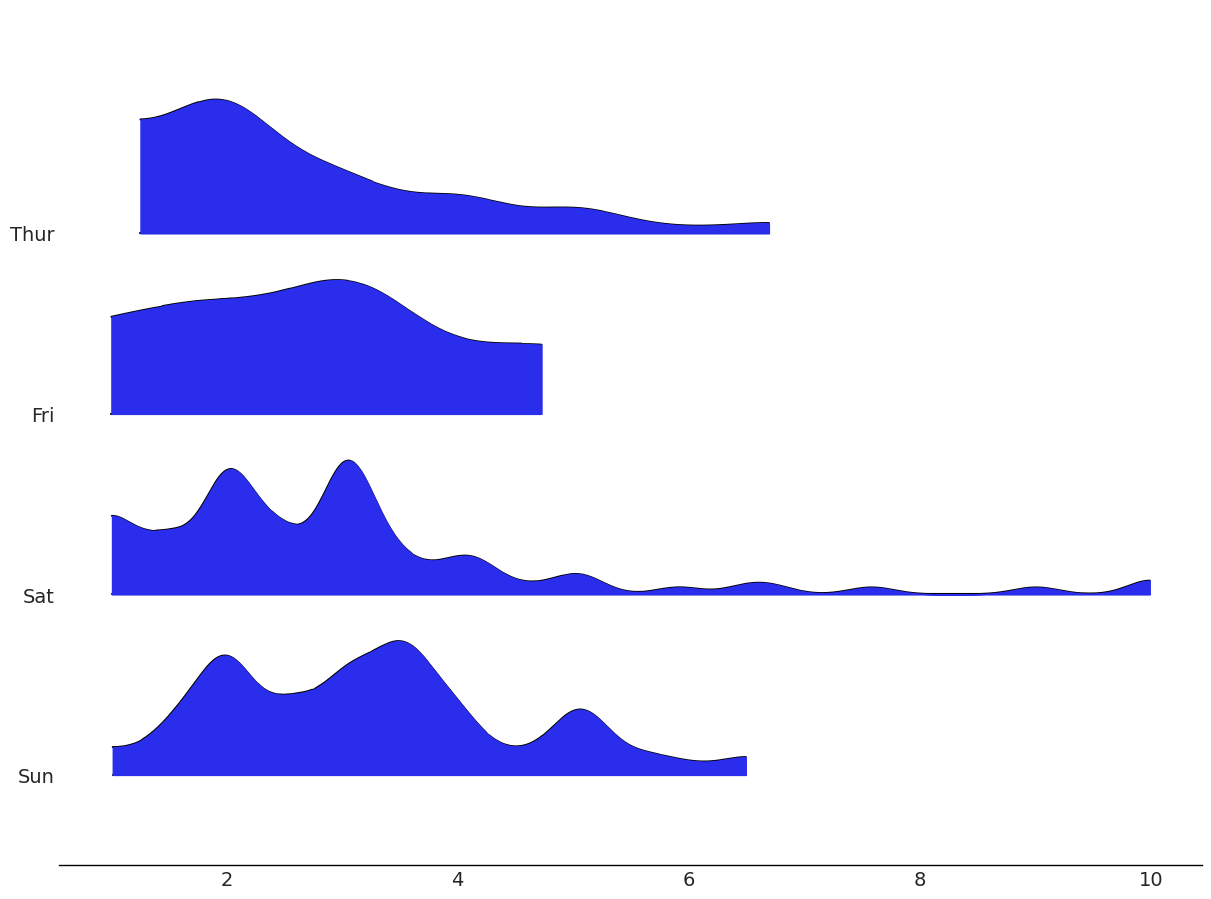

In [22]:
az.plot_forest(tips.pivot(columns='day', values='tip').to_dict('list'),
               kind='ridgeplot',
               hdi_prob=1);


In [9]:
categories = np.array(['Thur', 'Fri', 'Sat', 'Sun'])

tip = tips['tip'].values
idx = pd.Categorical(tips['day'], categories=categories).codes

In [10]:
categories, idx

(array(['Thur', 'Fri', 'Sat', 'Sun'], dtype='<U4'),
 array([3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 3, 3, 3, 3, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 3, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 3, 3, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 0], dtype=int8))

In [11]:
categories[idx][:10]

array(['Sun', 'Sun', 'Sun', 'Sun', 'Sun', 'Sun', 'Sun', 'Sun', 'Sun',
       'Sun'], dtype='<U4')

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [μ, σ]


C:\Users\Eshel\anaconda3\envs\bayes\Lib\site-packages\rich\live.py:231: UserWarning: install "ipywidgets" for 
Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1375 seconds.


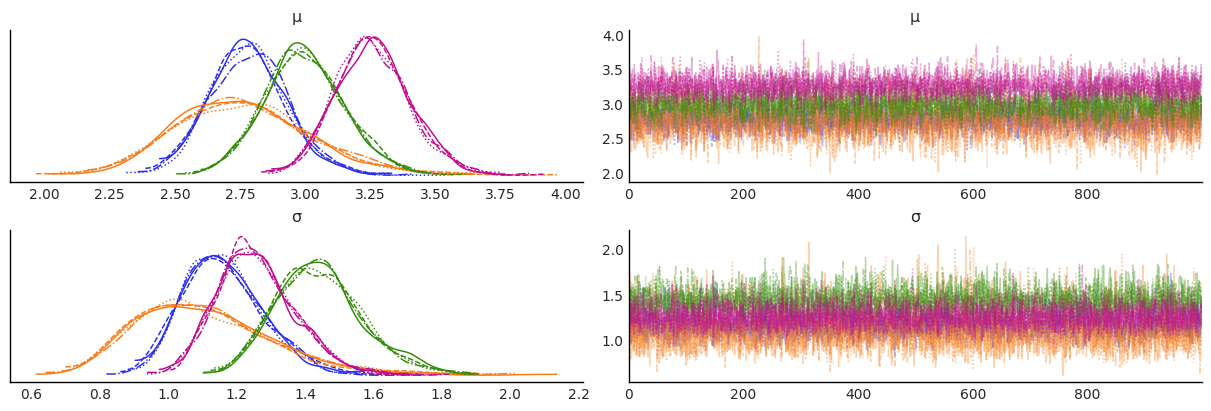

In [12]:
coords = {"days": categories, "days_flat":categories[idx]}

with pm.Model(coords=coords) as comparing_groups:
    μ = pm.HalfNormal('μ', sigma=5, dims="days")
    σ = pm.HalfNormal('σ', sigma=1, dims="days")

    y = pm.Gamma('y', mu=μ[idx], sigma=σ[idx], observed=tip, dims="days_flat")

    idata_cg = pm.sample()
    # idata_cg.extend(pm.sample_posterior_predictive(idata_cg))
az.plot_trace(idata_cg)
plt.savefig('B11197_02_17.png')

In [13]:
idata_cg.posterior['μ'].sel(days="Thur")

<xarray.DataArray 'μ' (chain: 4, draw: 1000)> Size: 32kB
array([[2.54049825, 2.75416362, 2.92752649, ..., 2.87796356, 2.7863897 ,
        2.75438449],
       [2.96466513, 2.91277116, 2.99617824, ..., 3.14280197, 2.84591311,
        2.83003543],
       [2.69269207, 2.77820351, 2.77778964, ..., 2.68105962, 2.98292587,
        2.69765765],
       [2.8916493 , 3.08219471, 3.1771319 , ..., 3.08214882, 2.88897765,
        3.11696534]], shape=(4, 1000))
Coordinates:
  * chain    (chain) int64 32B 0 1 2 3
  * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
    days     <U4 16B 'Thur'

In [35]:
idata_cg.posterior['μ'][0,:,0].mean()

<xarray.DataArray 'μ' ()>
array(2.77868211)
Coordinates:
    chain    int64 0
    days     <U4 'Thur'

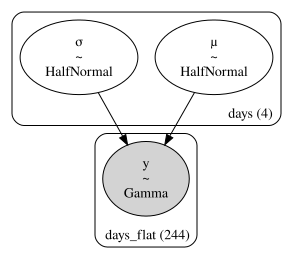

In [26]:
pm.model_to_graphviz(comparing_groups)

In [27]:
idata_cg.posterior['μ'].shape

(2, 1000, 4)

### We wish to find the difference between the difference days. Presenting just the difference between the average values of tips is not enough, we wish to conduct a more thourough comperison. For this purpose we introduce Cehen's effect size, also known as 'Cohen's d'.

### Cohen's effect size is a measure used in statistics to quantify the size of the difference between two groups. It was introduced by Jacob Cohen and is particularly common in the context of comparing means in experimental and observational studies. Cohen's effect size is often denoted by the symbol  $d$  and is calculated using the formula:

## $$  d= \frac{\mu_1-\mu_2}{S_{pooled}} $$

## Here's a breakdown of the components of the formula:

## 1. $\mu_1$ and $\mu_2$  are the averages of the two groups being compared.

## 2. $S_{pooled}$: This is a weighted average of the standard deviations of the two groups. The formula for the pooled standard deviation is:

## $$ S_{pooled} = \sqrt{\frac{(n_1-1)s_1^2+(n_2-1)s_2^2}{n_1+n_2-2}} $$



## where $n_1$ and $n_2$ are  the sample sizes of Group 1 and Group 2,  and $s_1$ and $s_2$ are their respective standard deviations.

## when $n_1=n_2$, then:

## $$ S_{pooled} = \sqrt{\frac{s_1^2+s_2^2}{2}} $$


### The resulting $d$ value represents the number of standard deviations by which the means of the two groups differ. Generally, larger values of  $d$ indicate a larger effect size, suggesting a more substantial difference between the groups.

### Cohen's guidelines for interpreting the effect size are:

* Small effect: $0.2 \leq |d| \leq 0.5$
* Medium effect: $0.5 \leq |d| \leq 0.8$
* Large effect: $|d| \geq 0.8$

## Interpreting effect sizes alongside statistical significance helps provide a more comprehensive understanding of the practical significance of observed differences in a study.






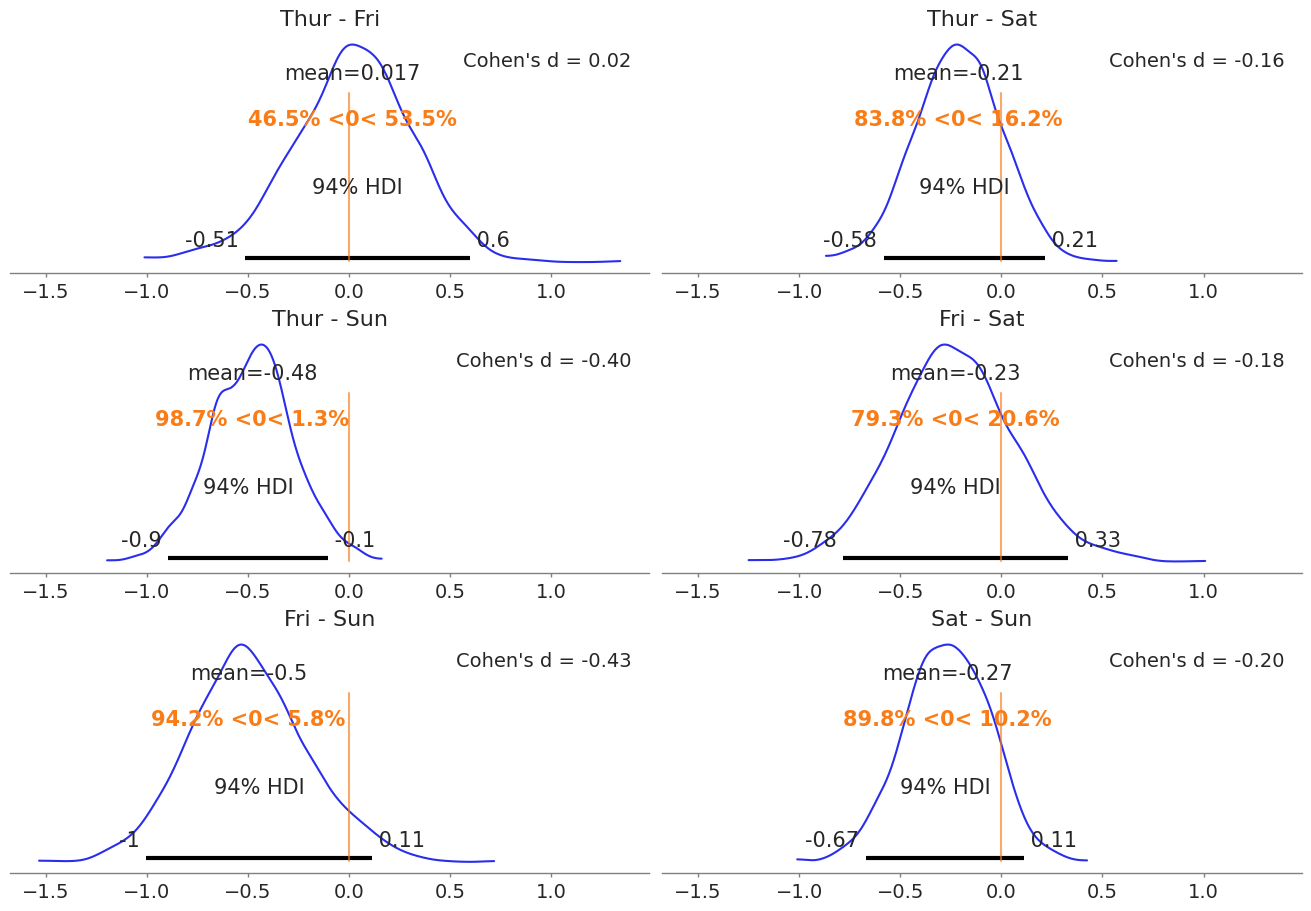

In [28]:
cg_posterior = az.extract(idata_cg)

dist = stats.norm()

comparisons = [(categories[i], categories[j]) for i in range(4) for j in range(i+1, 4)]

_, axes = plt.subplots(3, 2, figsize=(13, 9), sharex=True)

for (i, j), ax in zip(comparisons, axes.ravel()):
    means_diff = cg_posterior['μ'].sel(days=i) - cg_posterior['μ'].sel(days=j)

    d_cohen = (means_diff /
               np.sqrt((cg_posterior['σ'].sel(days=i)**2 +
                        cg_posterior['σ'].sel(days=j)**2) / 2)
              ).mean().item()

    az.plot_posterior(means_diff.values, ref_val=0, ax=ax)
    ax.set_title(f"{i} - {j}")
    ax.plot(0, label=f"Cohen's d = {d_cohen:.2f}", alpha=0)
    ax.legend(loc=1)
plt.savefig('B11197_02_18.png')